# Task 2: Wine Quality Prediction

**Objective:** train and compare multiple classification models (Random Forest, SGD and SVC) to predict the quality of a wine from its physicochemical properties such as acidity, density and alcohol content.

**Tech stack:** Python, pandas, numpy, scikit-learn, seaborn, matplotlib

**Dataset:** UCI Wine Quality dataset, red wine (`winequality-red.csv`) and white wine (`winequality-white.csv`). Each row is one wine, described by 11 lab measurements and a quality score given by tasters.

## 1. Importing libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

## 2. Loading the data and inspecting the structure

Both files use a semicolon (`;`) as separator. I load them separately, add a `wine_type` column (0 = red, 1 = white) and stack them into one dataset. The red and white wines have the same 11 features, so combining them gives more data, and the `wine_type` column lets the model account for any difference between the two.

In [2]:
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

red["wine_type"] = 0
white["wine_type"] = 1

print("Red wine   :", red.shape)
print("White wine :", white.shape)

df = pd.concat([red, white], ignore_index=True)
print("Combined   :", df.shape)
df.head()

Red wine   : (1599, 13)
White wine : (4898, 13)
Combined   : (6497, 13)


   fixed acidity  volatile acidity  citric acid  ...  alcohol  quality  wine_type
0            7.4              0.70         0.00  ...      9.4        5          0
1            7.8              0.88         0.00  ...      9.8        5          0
2            7.8              0.76         0.04  ...      9.8        5          0
3           11.2              0.28         0.56  ...      9.8        6          0
4            7.4              0.70         0.00  ...      9.4        5          0

[5 rows x 13 columns]

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 1177


**What I noticed:**
- There are **no missing values** and all columns are numeric, so no imputation or encoding is needed.
- There are **1,177 duplicate rows** (about 18%). In this dataset a duplicate is usually two different bottles that happen to have identical lab values and score, so they are not "wrong". But if I keep them, the same row can end up in both the training and the test set, and the test score would look better than it really is (data leakage). I therefore **drop the duplicates** before modelling.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (5320, 13)


In [6]:
df.describe().T.round(3)

                       count     mean     std  ...      50%      75%      max
fixed acidity         5320.0    7.215   1.320  ...    7.000    7.700   15.900
volatile acidity      5320.0    0.344   0.168  ...    0.300    0.410    1.580
citric acid           5320.0    0.318   0.147  ...    0.310    0.400    1.660
residual sugar        5320.0    5.048   4.500  ...    2.700    7.500   65.800
chlorides             5320.0    0.057   0.037  ...    0.047    0.066    0.611
free sulfur dioxide   5320.0   30.037  17.805  ...   28.000   41.000  289.000
total sulfur dioxide  5320.0  114.109  56.774  ...  116.000  153.250  440.000
density               5320.0    0.995   0.003  ...    0.995    0.997    1.039
pH                    5320.0    3.225   0.160  ...    3.210    3.330    4.010
sulphates             5320.0    0.533   0.150  ...    0.510    0.600    2.000
alcohol               5320.0   10.549   1.186  ...   10.400   11.400   14.900
quality               5320.0    5.796   0.880  ...    6.000    6

### 2.1 Class distribution of the quality scores

quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64

quality
3     0.56
4     3.87
5    32.93
6    43.67
7    16.09
8     2.78
9     0.09
Name: proportion, dtype: float64


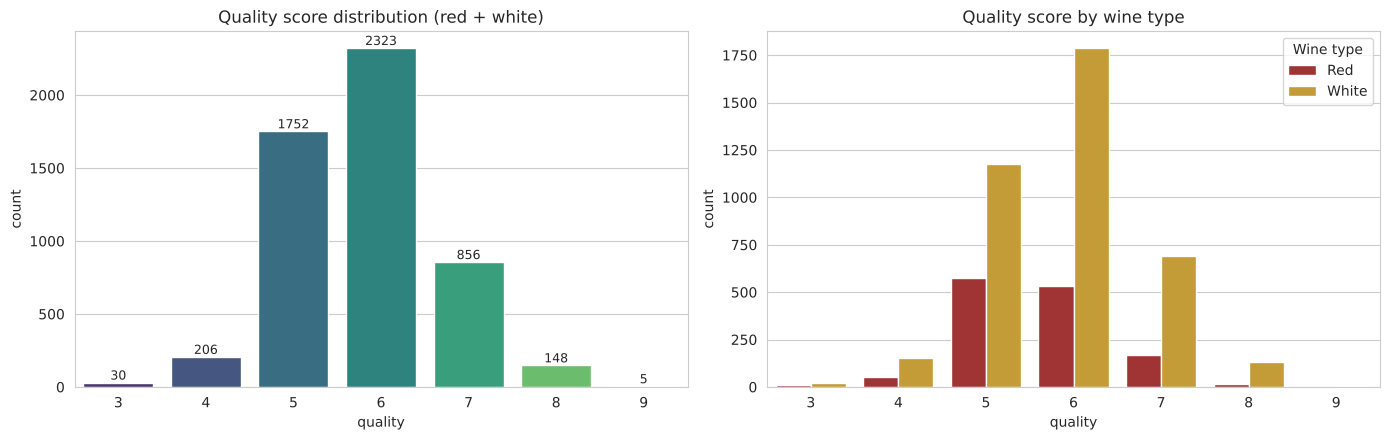

In [7]:
print(df["quality"].value_counts().sort_index())
print()
print((df["quality"].value_counts(normalize=True).sort_index() * 100).round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

sns.countplot(data=df, x="quality", palette="viridis", ax=ax[0])
ax[0].set_title("Quality score distribution (red + white)")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom", fontsize=9)

sns.countplot(data=df, x="quality", hue="wine_type", palette=["firebrick", "goldenrod"], ax=ax[1])
ax[1].set_title("Quality score by wine type")
ax[1].legend(title="Wine type", labels=["Red", "White"])

plt.tight_layout()
plt.show()

**Insight:**
- The scores range from 3 to 9, but most wines sit in the middle: scores **5 and 6 make up about 77%** of all the data (6 is the most common).
- The extremes are very rare. Only a handful of wines have a score of 3 or 9, and score 8 is also uncommon. So this is a clearly **imbalanced** problem (more on this in section 4).
- Red and white wines follow a similar shape, but white wines have slightly higher scores on average (about 5.85 vs 5.62).

## 3. Exploratory Data Analysis

### 3.1 Distribution of all chemical features

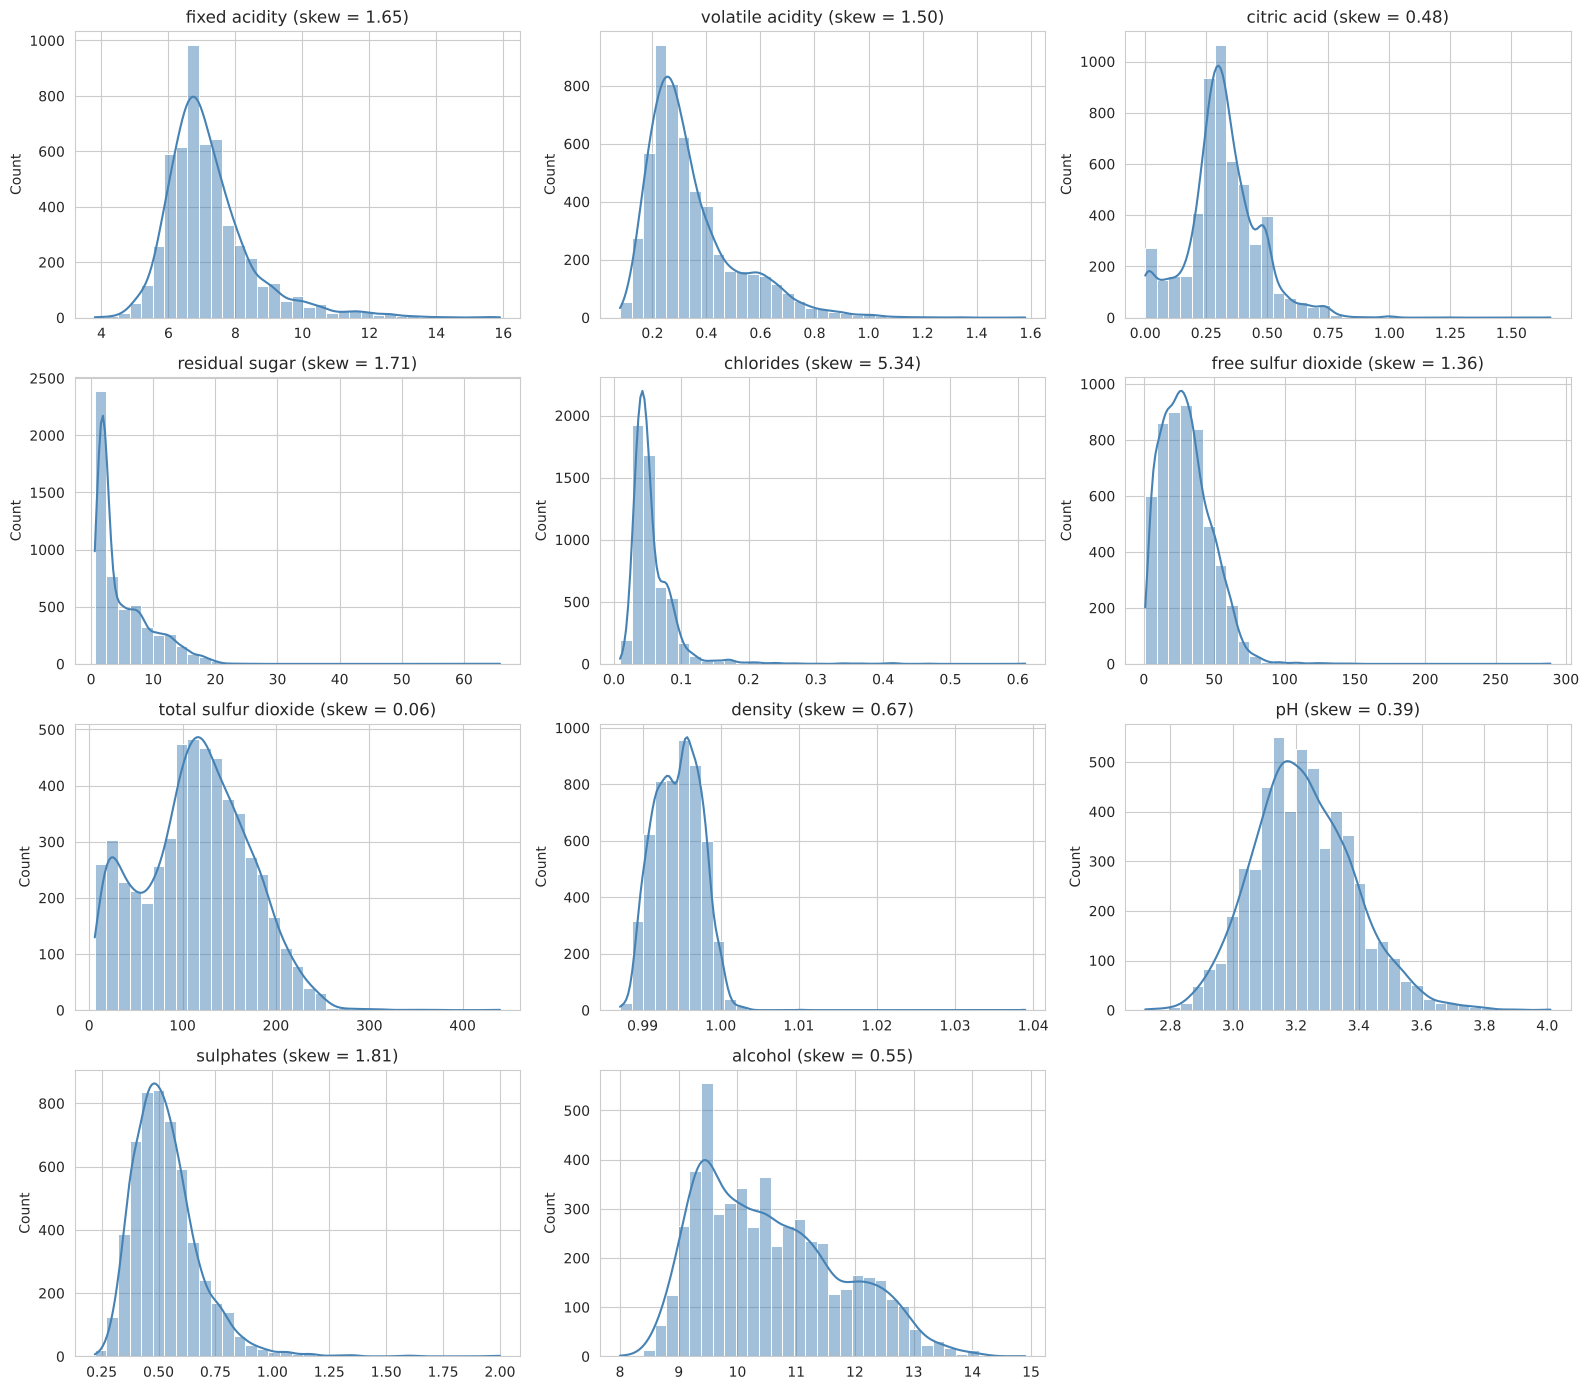

In [8]:
features = [c for c in df.columns if c not in ["quality", "wine_type"]]

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.histplot(df[col], bins=35, kde=True, color="steelblue", ax=axes[i])
    axes[i].set_title(f"{col} (skew = {df[col].skew():.2f})")
    axes[i].set_xlabel("")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

**Insight:**
- Most features are **right skewed**. The most extreme is `chlorides` (skew about 5.3), followed by `sulphates`, `residual sugar`, `fixed acidity` and `volatile acidity` (all 1.5 to 1.8). This means a few wines have very high values compared to the rest.
- `alcohol`, `density`, `pH`, `citric acid` and `total sulfur dioxide` are fairly close to symmetric.
- The features are on very different scales (density is around 0.99 while total sulfur dioxide goes up to 400), so **scaling is needed for SGD and SVC**, which are distance and gradient based. Random Forest does not care about scale or skewness.

### 3.2 Outliers and how the key features change with quality

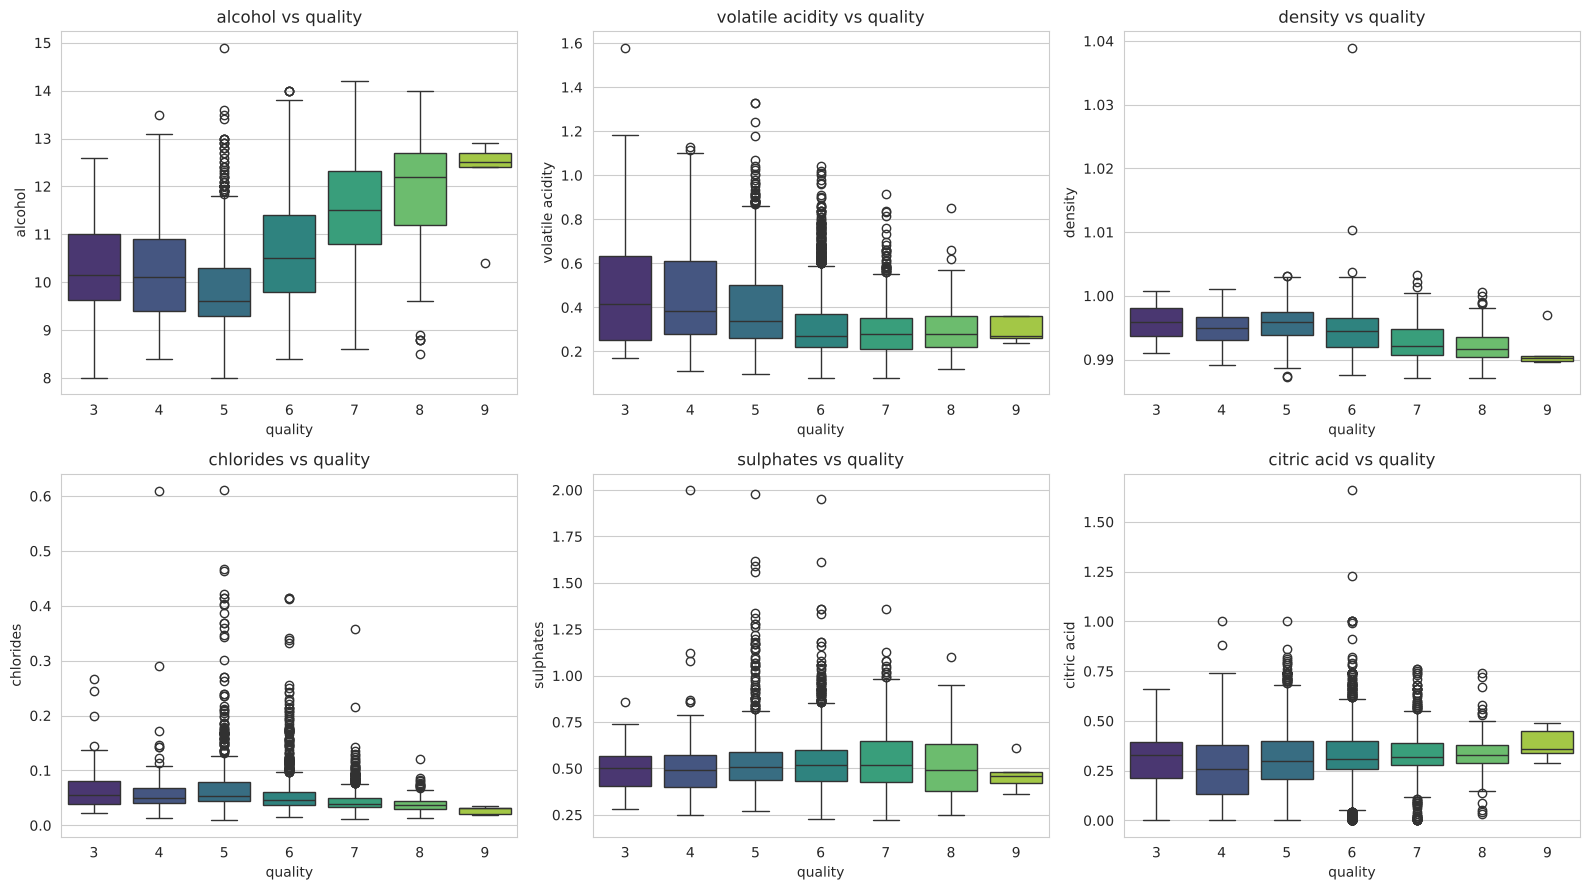

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for a, col in zip(axes.flatten(), ["alcohol", "volatile acidity", "density", "chlorides", "sulphates", "citric acid"]):
    sns.boxplot(data=df, x="quality", y=col, palette="viridis", ax=a)
    a.set_title(f"{col} vs quality")
plt.tight_layout()
plt.show()

**Insight:**
- **Alcohol** clearly goes up with quality: higher scoring wines have a higher alcohol percentage.
- **Volatile acidity** (the vinegar-like taste) and **chlorides** go down as quality goes up, which fits with them being "defects".
- **Density** also goes down with quality. This is mostly because alcohol is lighter than water, so more alcohol means a lower density.
- There are quite a few outliers (especially in `chlorides` and `sulphates`). I keep them because they are real measurements and not obvious data errors, and Random Forest and scaled SVC can handle them reasonably well.

### 3.3 Correlation heatmap

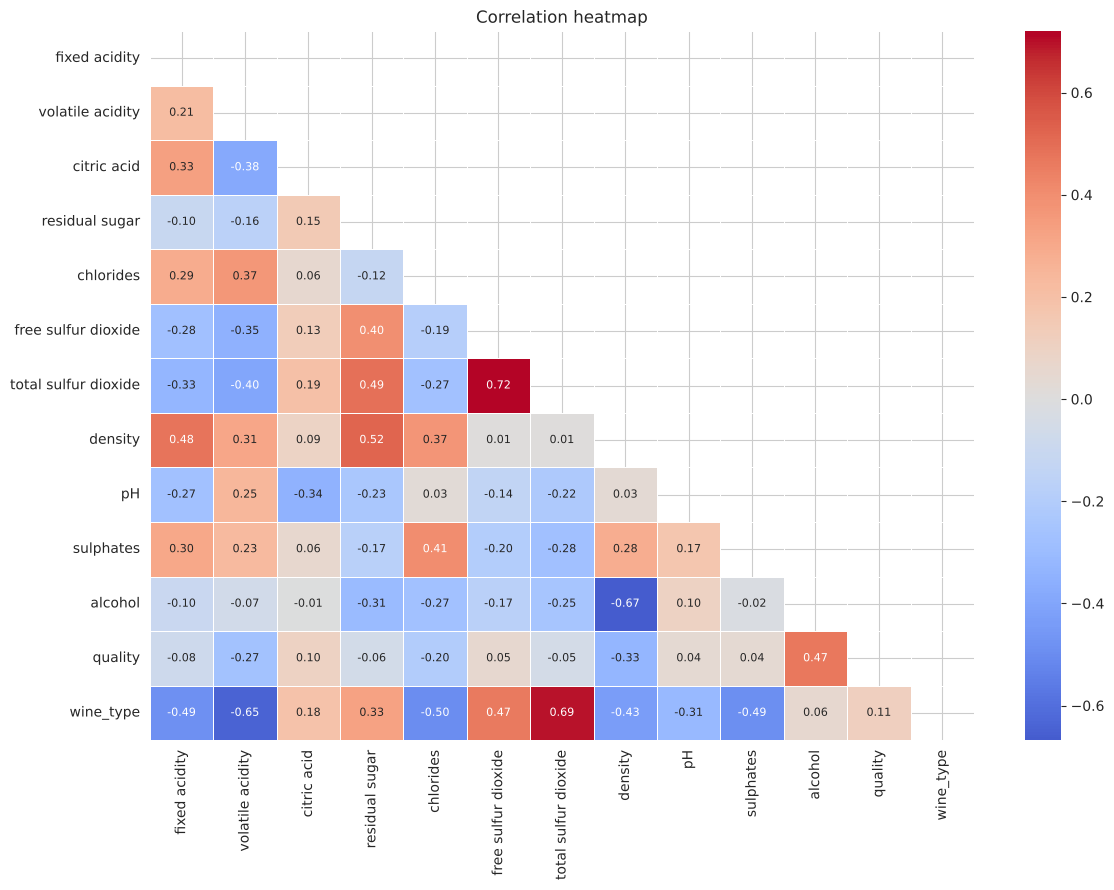

In [10]:
corr = df.corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, annot_kws={"size": 8})
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

density                -0.326
volatile acidity       -0.265
chlorides              -0.202
fixed acidity          -0.080
residual sugar         -0.057
total sulfur dioxide   -0.050
pH                      0.040
sulphates               0.042
free sulfur dioxide     0.054
citric acid             0.098
wine_type               0.115
alcohol                 0.469
Name: quality, dtype: float64


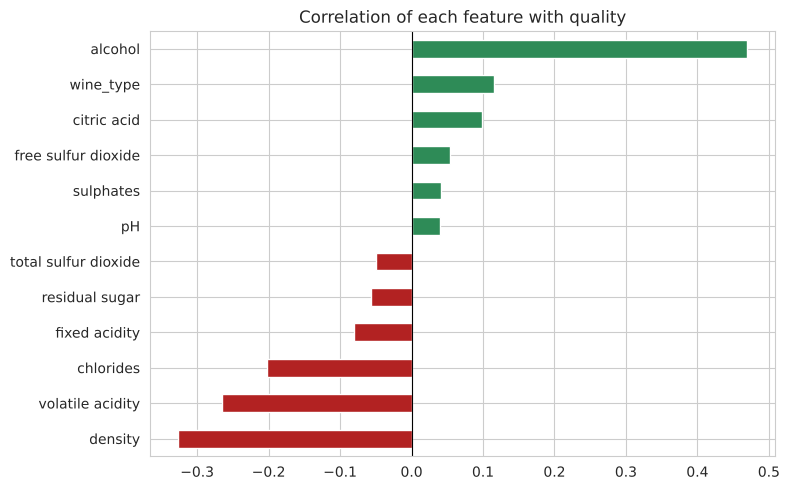

In [11]:
q_corr = corr["quality"].drop("quality").sort_values()

plt.figure(figsize=(8, 5))
q_corr.plot(kind="barh", color=["firebrick" if v < 0 else "seagreen" for v in q_corr])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation of each feature with quality")
plt.tight_layout()
plt.show()

print(q_corr.round(3))

**Insight:**
- **Alcohol** is the strongest positive correlation with quality (about +0.47). After that come `density` (-0.33), `volatile acidity` (-0.27) and `chlorides` (-0.20).
- Even the best feature is only moderately correlated, and several features (`pH`, `sulphates`, `free sulfur dioxide`) are close to zero. So quality is not explained by one or two chemical values, and we should not expect a very high accuracy.
- Some features are strongly related to each other: `density` is linked with `alcohol` (negative) and with `residual sugar` and `fixed acidity` (positive), and `free sulfur dioxide` goes with `total sulfur dioxide`. This overlap is not a problem for Random Forest, but it means the importance can be split between related features.

## 4. Class imbalance discussion

**Are some quality scores underrepresented?** Yes. Out of the 5,320 unique wines, the extreme scores (3, 4, 8 and 9) have very few samples, while 5 and 6 have thousands.

**How does this affect modelling?**
- A model can get a good-looking **accuracy just by predicting the common classes** (5 and 6) and ignoring the rare ones. Accuracy alone would hide this, so I also look at the per-class precision/recall and the macro F1 score, which treats every class equally.
- With only a few examples of scores 3 and 9, the model cannot learn what those wines look like, and a stratified split could even leave only one or two of them in the test set, making the test metrics for those classes meaningless.
- Ways to handle it: group the scores into fewer classes (done below), use `class_weight="balanced"` so mistakes on rare classes cost more, and use stratified splitting and stratified cross validation.

## 5. Feature engineering: binning the quality score

Predicting the exact score from 3 to 9 is not practical here, because some of those classes have only a few samples, and the difference between neighbouring scores (say 5 and 6) is quite subjective since it comes from human tasters. I group the scores into **3 classes**:

| Class | Quality score | Meaning |
|---|---|---|
| 0 | 3, 4, 5 | Low |
| 1 | 6 | Medium |
| 2 | 7, 8, 9 | High |

**Why 3 classes and not binary (good/bad)?**
- The groups are much more balanced (about 37% / 44% / 19%) than the original 7 classes, and every group has plenty of samples.
- A 3-class version keeps more useful information than a simple good/bad split. A buyer or producer would care about telling average wines from poor ones, and not only about spotting the top ones.
- A binary split (for example `quality >= 7` as good) would be 81% vs 19%, which is again imbalanced. I still test it at the end as an extra experiment.

quality_group
0    37.37
1    43.67
2    18.97
Name: proportion, dtype: float64


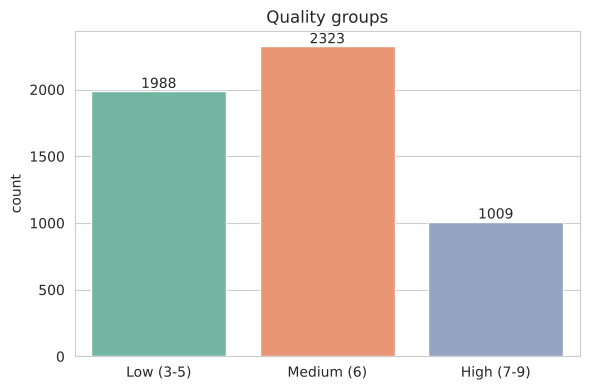

In [12]:
def quality_group(q):
    if q <= 5:
        return 0   # Low
    elif q == 6:
        return 1   # Medium
    else:
        return 2   # High

df["quality_group"] = df["quality"].apply(quality_group)
label_names = ["Low (3-5)", "Medium (6)", "High (7-9)"]

print((df["quality_group"].value_counts(normalize=True).sort_index() * 100).round(2))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x=df["quality_group"].map(dict(enumerate(label_names))),
                   order=label_names, palette="Set2")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Quality groups")
plt.xlabel("")
plt.tight_layout()
plt.show()

## 6. Stratified train/test split (80/20)

In [13]:
X = df.drop(columns=["quality", "quality_group"])
y = df["quality_group"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)

# check that stratify kept the class ratios
ratios = pd.DataFrame({
    "Full data": y.value_counts(normalize=True).sort_index(),
    "Train": y_train.value_counts(normalize=True).sort_index(),
    "Test": y_test.value_counts(normalize=True).sort_index()
}).round(3)
ratios.index = label_names
ratios

Train: (4256, 12)  Test: (1064, 12)


            Full data  Train   Test
Low (3-5)       0.374  0.374  0.373
Medium (6)      0.437  0.437  0.437
High (7-9)      0.190  0.190  0.190

The class proportions are almost identical in the full data, training set and test set, so the stratified split worked.

## 7. Training the three classifiers

- **Random Forest**: an ensemble of decision trees. It needs no scaling and handles skewed data and feature interactions well.
- **SGD Classifier**: a linear model trained with stochastic gradient descent (with `log_loss` it is basically logistic regression). It is very fast, but can only draw straight decision boundaries.
- **SVC**: a support vector classifier with an RBF kernel, which can learn curved boundaries.

Setup used for fairness:
- SGD and SVC are wrapped in a **pipeline with `StandardScaler`**, so scaling is learned from the training data only (no leakage into the test set).
- All three use `class_weight="balanced"` to deal with the imbalance.
- Each model gets a **small grid search** with 5-fold stratified cross validation, optimised for **macro F1** (so that no class is ignored). The test set is not touched until the final evaluation.
- Before that, a **dummy model** that always predicts the most common class gives the minimum score any model has to beat.

In [14]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
print(f"Dummy (always 'Medium') accuracy: {accuracy_score(y_test, dummy_pred):.3f}")
print(f"Dummy macro F1                  : {f1_score(y_test, dummy_pred, average='macro'):.3f}")

Dummy (always 'Medium') accuracy: 0.437
Dummy macro F1                  : 0.203


In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Random Forest": (
        Pipeline([("model", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                   random_state=RANDOM_STATE))]),
        {"model__max_depth": [None, 20], "model__min_samples_leaf": [1, 2]}
    ),
    "SGD Classifier": (
        Pipeline([("scaler", StandardScaler()),
                  ("model", SGDClassifier(class_weight="balanced", max_iter=3000,
                                          random_state=RANDOM_STATE))]),
        {"model__loss": ["hinge", "log_loss"], "model__alpha": [1e-4, 1e-3, 1e-2]}
    ),
    "SVC": (
        Pipeline([("scaler", StandardScaler()),
                  ("model", SVC(class_weight="balanced", random_state=RANDOM_STATE))]),
        {"model__C": [1, 10], "model__gamma": ["scale", 0.1]}
    ),
}

best_models = {}
for name, (pipe, grid) in models.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    print(f"{name:15s} best CV macro F1 = {gs.best_score_:.3f} | best params = {gs.best_params_}")

Random Forest   best CV macro F1 = 0.618 | best params = {'model__max_depth': 20, 'model__min_samples_leaf': 1}
SGD Classifier  best CV macro F1 = 0.561 | best params = {'model__alpha': 0.01, 'model__loss': 'log_loss'}
SVC             best CV macro F1 = 0.574 | best params = {'model__C': 10, 'model__gamma': 0.1}


Cross validation macro F1 is about 0.62 for Random Forest, 0.57 for SVC and 0.56 for SGD, so the ranking is already visible before we look at the test set.

## 8. Evaluation on the test set

For each model: accuracy, classification report (precision, recall, F1 per class) and confusion matrix.

In [16]:
results = {}
preds = {}

for name, model in best_models.items():
    pred = model.predict(X_test)
    preds[name] = pred
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Weighted F1": f1_score(y_test, pred, average="weighted"),
    }
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(f"Accuracy: {results[name]['Accuracy']:.4f}\n")
    print(classification_report(y_test, pred, target_names=label_names, digits=3))

Random Forest
Accuracy: 0.5921

              precision    recall  f1-score   support

   Low (3-5)      0.643     0.715     0.677       397
  Medium (6)      0.561     0.473     0.513       465
  High (7-9)      0.548     0.624     0.583       202

    accuracy                          0.592      1064
   macro avg      0.584     0.604     0.591      1064
weighted avg      0.589     0.592     0.588      1064

SGD Classifier
Accuracy: 0.5667

              precision    recall  f1-score   support

   Low (3-5)      0.621     0.710     0.663       397
  Medium (6)      0.550     0.441     0.489       465
  High (7-9)      0.489     0.574     0.528       202

    accuracy                          0.567      1064
   macro avg      0.553     0.575     0.560      1064
weighted avg      0.565     0.567     0.561      1064

SVC
Accuracy: 0.5799

              precision    recall  f1-score   support

   Low (3-5)      0.632     0.730     0.678       397
  Medium (6)      0.593     0.370     0.45

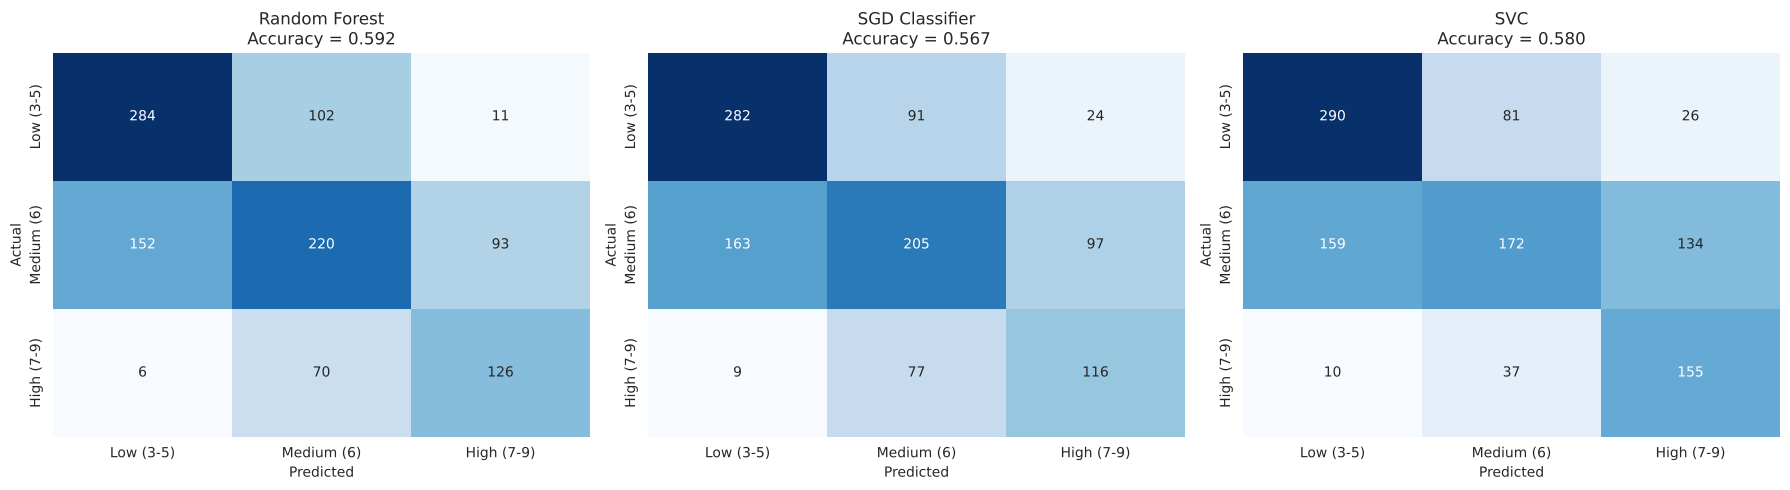

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=label_names, yticklabels=label_names, ax=ax)
    ax.set_title(f"{name}\nAccuracy = {results[name]['Accuracy']:.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

**Insight:**
- **Random Forest** is the best on the test set: accuracy about 59.2% and macro F1 about 0.59. **SVC** follows (58.0% accuracy, macro F1 0.58) and **SGD** is last (56.7%, macro F1 0.56). All three clearly beat the dummy model (about 44% accuracy).
- In every confusion matrix the **Medium (6) class is the hardest**. Many Medium wines get predicted as Low or High, because a "6" is by definition between the two and sits right next to both. SVC is the extreme example: it catches High wines very well (recall about 77%) but only 37% of the Medium wines.
- **Mistakes are mostly between neighbouring classes.** A Low wine is almost never predicted as High and the other way round (for Random Forest only 6 High wines were called Low and 11 Low wines were called High). That is a good sign: when the model is wrong, it is usually wrong by one step.
- Random Forest has the most even performance across the three classes, which is why it has the best macro F1.
- Accuracy around 59% is not high, but it is expected: the ratings come from human tasters, and the correlation analysis already showed that no single lab value explains quality strongly.

## 9. Feature importance (Random Forest)

alcohol                 0.157
density                 0.106
volatile acidity        0.099
chlorides               0.087
total sulfur dioxide    0.087
sulphates               0.082
free sulfur dioxide     0.081
citric acid             0.077
pH                      0.076
residual sugar          0.075
fixed acidity           0.069
wine_type               0.004
dtype: float64


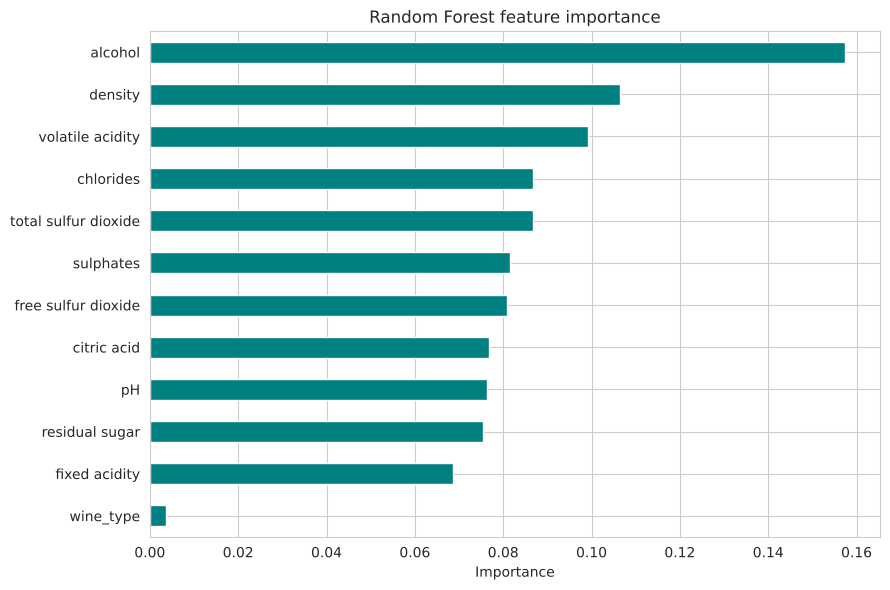

In [18]:
rf_model = best_models["Random Forest"][-1]
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(9, 6))
importance.plot(kind="barh", color="teal")
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False).round(3))

**Insight:**
- **Alcohol** is the most important feature (about 0.16), followed by `density` (0.11) and `volatile acidity` (0.10). This agrees with the correlation analysis and the boxplots.
- The rest of the chemical features (`chlorides`, `total sulfur dioxide`, `sulphates`, `free sulfur dioxide`, `citric acid`, `pH`) have similar importance of 0.08 to 0.09, so quality depends on a combination of many factors and not on a few.
- `wine_type` is almost zero (about 0.004), so once the chemistry is known, it hardly matters whether the wine is red or white. This supports the decision to train one combined model.
- One caution: since `density` and `alcohol` are related, part of the importance of one may really belong to the other.

## 10. Model comparison

In [19]:
comparison = pd.DataFrame(results).T
comparison["Medium-class recall"] = [
    classification_report(y_test, preds[m], output_dict=True)["1"]["recall"] for m in comparison.index]
comparison["High-class recall"] = [
    classification_report(y_test, preds[m], output_dict=True)["2"]["recall"] for m in comparison.index]
comparison.loc["Dummy baseline"] = [
    accuracy_score(y_test, dummy_pred), f1_score(y_test, dummy_pred, average="macro"),
    f1_score(y_test, dummy_pred, average="weighted"), 1.0, 0.0]
comparison.round(3)

                Accuracy  Macro F1  ...  Medium-class recall  High-class recall
Random Forest      0.592     0.591  ...                0.473              0.624
SGD Classifier     0.567     0.560  ...                0.441              0.574
SVC                0.580     0.578  ...                0.370              0.767
Dummy baseline     0.437     0.203  ...                1.000              0.000

[4 rows x 5 columns]

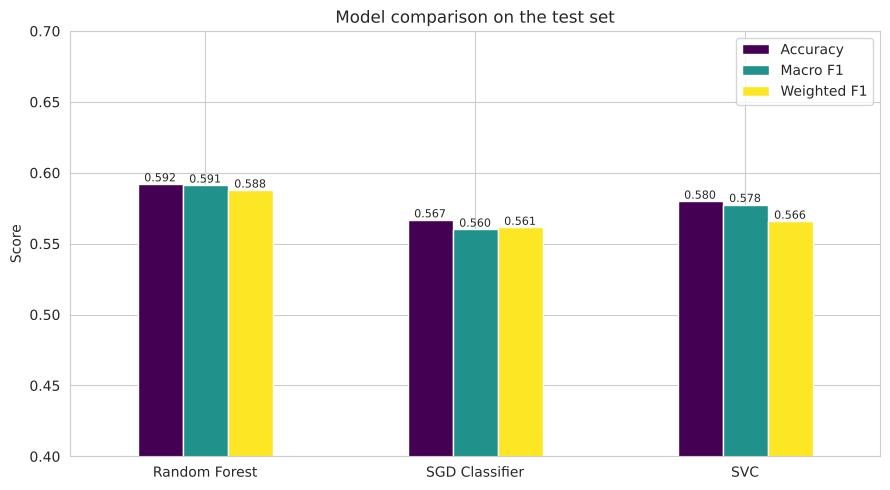

In [20]:
plot_df = comparison.drop(index="Dummy baseline")[["Accuracy", "Macro F1", "Weighted F1"]]
ax = plot_df.plot(kind="bar", figsize=(9, 5), colormap="viridis", rot=0)
ax.set_ylim(0.4, 0.7)
ax.set_title("Model comparison on the test set")
ax.set_ylabel("Score")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.show()

## 11. Extra experiment: what if we use a binary target (good vs not good)?

To check the binning decision, I repeat the experiment with a binary target: **good = quality 7 or more**. I use the default settings (with scaling and balanced class weights), no tuning, just to compare.

In [21]:
y_bin = (df["quality"] >= 7).astype(int)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X, y_bin, test_size=0.2, stratify=y_bin, random_state=RANDOM_STATE)

bin_models = {
    "Random Forest": Pipeline([("model", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE))]),
    "SGD Classifier": Pipeline([("scaler", StandardScaler()), ("model", SGDClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
    "SVC": Pipeline([("scaler", StandardScaler()), ("model", SVC(class_weight="balanced", random_state=RANDOM_STATE))]),
}

rows = {}
for name, m in bin_models.items():
    m.fit(Xb_train, yb_train)
    p = m.predict(Xb_test)
    rep = classification_report(yb_test, p, output_dict=True)
    rows[name] = {"Accuracy": accuracy_score(yb_test, p), "Macro F1": f1_score(yb_test, p, average="macro"),
                  "Good-wine recall": rep["1"]["recall"], "Good-wine precision": rep["1"]["precision"]}

print("Share of 'good' wines:", round(y_bin.mean() * 100, 1), "%")
pd.DataFrame(rows).T.round(3)

Share of 'good' wines: 19.0 %


                Accuracy  Macro F1  Good-wine recall  Good-wine precision
Random Forest      0.838     0.748             0.634                0.566
SGD Classifier     0.725     0.636             0.609                0.365
SVC                0.737     0.680             0.832                0.406

**Insight:** Binary accuracy looks higher (around 72% to 84%), but that number is misleading, because 81% of wines are "not good". A model that always says "not good" would already get about 81%. The Random Forest is the only one that keeps both a high accuracy and a good macro F1 (about 0.75), and it again beats SGD and SVC. SVC catches the most good wines (recall about 83%) but many of its "good" predictions are wrong (precision about 41%), which is why its accuracy drops. The 3-class version is harder, but it is more informative, so I keep it as the main result.

## 12. Conclusion

**What I did:** combined the red and white datasets, removed duplicates, explored the features and correlations, handled the class imbalance by grouping the scores into 3 classes, used a stratified 80/20 split, tuned and trained Random Forest, SGD and SVC, and compared them with accuracy, classification reports and confusion matrices.

**Results summary (test set, 3 classes)**

| Model | Accuracy | Macro F1 |
|---|---|---|
| Dummy (always Medium) | about 0.44 | about 0.20 |
| SGD Classifier | about 0.567 | about 0.560 |
| SVC (RBF) | about 0.580 | about 0.578 |
| **Random Forest** | **about 0.592** | **about 0.591** |

**Which model is most suitable for deployment?** **Random Forest**, for these reasons:
1. It has the **best accuracy and macro F1**, and the best cross validation score as well, so the result is not a lucky split.
2. It is the most **balanced across classes**. SVC is better at finding High wines but misses many Medium ones, and SGD is weaker in every class.
3. It needs **no feature scaling** and is robust to skewed features and outliers, so the deployment pipeline is simpler and less likely to break.
4. It gives **feature importances**, so the producer can see that alcohol, density and volatile acidity matter most. That helps when explaining the model's decisions.
5. Prediction for a single wine is fast, and the model is small enough to deploy easily.

SGD is the fastest to train and the lightest, but it is limited to linear boundaries and was the least accurate. SVC is a reasonable second choice but is slower on larger datasets and needs scaling.

**Key findings**
- Alcohol is the strongest driver of quality. Higher alcohol is linked with higher quality, while higher volatile acidity, chlorides and density are linked with lower quality.
- The dataset is imbalanced (scores 5 and 6 are 77% of the data), so accuracy alone is not enough and macro F1 is a fairer metric.
- Most errors are between neighbouring classes, and the Medium class is the hardest to predict.

**Limitations and next steps**
- An accuracy of about 59% means the model should be used as a **support tool and not as a replacement for the taster**. Quality scores are subjective, and the lab values do not capture things like aroma and grape variety.
- Possible improvements: a wider hyperparameter search, gradient boosting models (XGBoost / LightGBM), handling the skewed features with log transforms for the linear models, and oversampling the rare classes (for example with SMOTE).
- With more data for the extreme scores (3, 4, 8, 9) the original 7-class problem could be attempted too.